# Representation diagnostics — five-seed analysis
**Read-only:** analyzes completed output files without training or modifying the original model.

This notebook deliberately separates historical evaluation from the expanded diagnostic question distribution. Every summary reports its denominator; random networks, shuffled-label probes, and invariant-label interventions are controls. Interpretation is conditional on reproducible five-seed evidence, not attractive heatmaps.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / 'outputs/medium_world/dataset'
OUT_DIR = PROJECT_ROOT / 'outputs/medium_world/experiments/representation_diagnostics/five_seeds'

SEEDS = (42, 43, 44, 45, 46)
SCHEDULES = ('prereq_mixed_pair_focus', 'mixed')
STEPS = (5400, 7200, 9000)
SPLITS = ('id_dev', 'ood_dev')

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from src.medium_visual_world.learning import MediumDataset, AttributeBindingViT
from src.medium_visual_world.representation_probing import (
    unique_question_rows, image_tensor, visual_stages,
    foreground_concept_masks, distinct_scenes, sha256_file,
)
manifest = pd.read_csv(OUT_DIR / 'checkpoint_manifest.csv')
assert len(manifest) == 30 and set(manifest.seed) == set(SEEDS)
audit = pd.read_csv(OUT_DIR / 'checkpoint_reproduction_audit.csv')
assert len(audit) == 60

def load_parts(pattern, expected):
    # Only load original per-checkpoint files, never summaries from a prior analysis run.
    prefix = pattern.split('*', 1)[0]
    schedule_pattern = '|'.join(map(re.escape, SCHEDULES))
    seed_pattern = '|'.join(map(str, SEEDS))
    step_pattern = '|'.join(map(str, STEPS))
    split_pattern = '|'.join(map(re.escape, SPLITS))
    source_name = re.compile(
        rf'^{re.escape(prefix)}(?:(?:{split_pattern})_)?'
        rf'(?:{schedule_pattern})_seed(?:{seed_pattern})_step(?:{step_pattern})'
        rf'(?:_(?:trained|random))?\.csv$'
    )
    paths = sorted(p for p in OUT_DIR.glob(pattern) if source_name.fullmatch(p.name))
    assert len(paths) == expected, (pattern, 'expected', expected, 'found', len(paths))
    frame = pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)
    required = ['schedule', 'seed', 'step', 'checkpoint_sha256']
    assert all(column in frame.columns for column in required), pattern
    observed = frame[required].drop_duplicates()
    assert not observed.duplicated(['schedule', 'seed', 'step']).any(), pattern
    expected_hashes = manifest[required].drop_duplicates()
    checked = observed.merge(
        expected_hashes,
        on=['schedule', 'seed', 'step'],
        suffixes=('_observed', '_expected'),
        validate='one_to_one',
        indicator=True
    )
    assert len(checked) == len(manifest) and checked['_merge'].eq('both').all(), (
        'Missing/extra checkpoint groups', pattern
    )
    assert checked['checkpoint_sha256_observed'].eq(
        checked['checkpoint_sha256_expected']
    ).all(), f'Checkpoint hash mismatch for {pattern}'
    return frame

def mean_sd_ci(frame, keys, value):
    from scipy.stats import t
    rows = []
    for labels, part in frame.groupby(keys, dropna=False):
        values = part.sort_values('seed')[value].to_numpy(float)
        if (
            len(values) != len(SEEDS)
            or set(part.seed) != set(SEEDS)
            or not np.isfinite(values).all()
        ):
            raise AssertionError(f'Five finite seeds expected for {labels}')
        mean = float(values.mean())
        sd = float(values.std(ddof=1))
        if sd == 0:
            low, high = mean, mean
        else:
            low, high = t.interval(0.95, 4, loc=mean, scale=sd / np.sqrt(5))
        key_vals = labels if isinstance(labels, tuple) else (labels,)
        rows.append(dict(zip(keys, key_vals)) | {
            'mean': mean,
            'sd_between_seeds': sd,
            'ci95_low': low,
            'ci95_high': high,
            'n_seeds': 5
        })
    return pd.DataFrame(rows)
original = pd.read_csv(OUT_DIR / 'original_checkpoint_performance.csv')
assert original.groupby(['schedule', 'step', 'split', 'task']).seed.nunique().eq(5).all()
print('Original benchmark accuracy (same original dev questions):')
display(original[original.step == 9000].groupby([
    'schedule',
    'split',
    'task'
]).accuracy.agg(['mean', 'std']).reset_index())
print('Archive reproduction check:')
display(audit.groupby(['schedule', 'split', 'status'], dropna=False).agg(
    n=('seed', 'size'),
    max_mismatched=('mismatched_predictions', 'max'),
    max_probability_delta=('max_probability_delta', 'max')
).reset_index())

def load_diagnostic_checkpoint(path):
    # Older checkpoints saved torch.__version__ as the TorchVersion str subclass.
    # Allowlist precisely that type while keeping restricted weights-only loading.
    with torch.serialization.safe_globals([torch.torch_version.TorchVersion]):
        return torch.load(path, map_location='cpu', weights_only=True)


Original benchmark accuracy (same original dev questions):


,schedule,split,task,mean,std
0,mixed,id_dev,color,0.992188,0.007813
1,mixed,id_dev,conjunction,0.797656,0.015722
2,mixed,id_dev,pair,0.620313,0.044658
3,mixed,id_dev,shape,0.678125,0.013131
4,mixed,ood_dev,pair,0.564500,0.033792
5,prereq_mixed_pair_focus,id_dev,color,0.993750,0.004454
6,prereq_mixed_pair_focus,id_dev,conjunction,0.807031,0.021679
7,prereq_mixed_pair_focus,id_dev,pair,0.630469,0.013975
8,prereq_mixed_pair_focus,id_dev,shape,0.668750,0.017986
9,prereq_mixed_pair_focus,ood_dev,pair,0.572500,0.026041


Archive reproduction check:


,schedule,split,status,n,max_mismatched,max_probability_delta
0,mixed,id_dev,compared,15,18,0.115732
1,mixed,ood_dev,compared,15,12,0.091661
2,prereq_mixed_pair_focus,id_dev,compared,15,6,0.046992
3,prereq_mixed_pair_focus,ood_dev,compared,15,3,0.036716


## 1. Same-scene capability matrix
Distinct question keys are used for task-level performance; the full Cartesian matrix is retained **only** for logical consistency across the same scene and target pair. For Shape × task comparisons, use Shape/Conjunction/Pair, never duplicated Color rows. Distinguish held-out target pairs and four logical cases.

In [3]:
questions = load_parts('same_scene_*.csv', 30 * len(SPLITS))
logic = load_parts('logical_consistency_*.csv', 30 * len(SPLITS))
unique = unique_question_rows(questions)
assert set(unique.seed) == set(SEEDS)
print('Original grid rows', len(questions), 'distinct queries', len(unique))
performance = unique.groupby(['schedule', 'seed', 'step', 'split', 'task'], dropna=False).agg(
    n_questions=('correct', 'size'),
    n_scenes=('scene_id', 'nunique'),
    accuracy=('correct', 'mean'),
    cross_entropy=('cross_entropy', 'mean'),
    positive_rate=('prediction', 'mean')
).reset_index()
performance.to_csv(OUT_DIR / 'same_scene_task_summary.csv', index=False)
display(performance[performance.step == 9000].groupby(['schedule', 'split', 'task']).agg(
    accuracy=('accuracy', 'mean'),
    min_questions=('n_questions', 'min'),
    n_seeds=('seed', 'nunique')
).reset_index().head(45))
subgroup = unique[unique.task.isin(['shape', 'conjunction', 'pair'])].groupby(
    [
        'schedule', 'seed', 'step', 'split', 'task', 'shape',
        'label', 'logic_case', 'heldout_target',
    ],
    dropna=False,
).agg(
    n_questions=('correct', 'size'),
    n_scenes=('scene_id', 'nunique'),
    accuracy=('correct', 'mean'),
    mean_prob_yes=('prob_yes', 'mean')
).reset_index()
subgroup['well_supported'] = subgroup.n_scenes >= 30
subgroup.to_csv(OUT_DIR / 'joint_subgroup_accuracy.csv', index=False)
print('Low-support cells (<30 distinct scenes):', int((~subgroup.well_supported).sum()))
display(subgroup[(subgroup.step == 9000) & (subgroup.task == 'conjunction')].sort_values('accuracy').head(25))

Original grid rows 2188800 distinct queries 1340640


,schedule,split,task,accuracy,min_questions,n_seeds
0,mixed,id_dev,color,0.992656,2560,5
1,mixed,id_dev,conjunction,0.812910,10240,5
2,mixed,id_dev,pair,0.732617,10240,5
3,mixed,id_dev,shape,0.652930,2048,5
4,mixed,ood_dev,color,0.992200,2000,5
5,mixed,ood_dev,conjunction,0.805050,8000,5
6,mixed,ood_dev,pair,0.717850,8000,5
7,mixed,ood_dev,shape,0.580500,1600,5
8,prereq_mixed_pair_focus,id_dev,color,0.992734,2560,5
9,prereq_mixed_pair_focus,id_dev,conjunction,0.811035,10240,5


Low-support cells (<30 distinct scenes): 0


,schedule,seed,step,split,task,shape,label,logic_case,heldout_target,n_questions,n_scenes,accuracy,mean_prob_yes,well_supported
2273,mixed,46,9000,ood_dev,conjunction,crescent,0,missing_shape,True,68,68,0.000000,0.788967,True
2197,mixed,46,9000,id_dev,conjunction,crescent,0,missing_shape,True,94,94,0.000000,0.800175,True
1261,mixed,44,9000,id_dev,conjunction,crescent,0,missing_shape,True,94,94,0.000000,0.936157,True
3677,prereq_mixed_pair_focus,44,9000,ood_dev,conjunction,crescent,0,missing_shape,True,68,68,0.000000,0.831318,True
3601,prereq_mixed_pair_focus,44,9000,id_dev,conjunction,crescent,0,missing_shape,True,94,94,0.000000,0.835925,True
1337,mixed,44,9000,ood_dev,conjunction,crescent,0,missing_shape,True,68,68,0.000000,0.947137,True
417,mixed,42,9000,ood_dev,conjunction,triangle,0,missing_shape,True,58,58,0.017241,0.731617,True
341,mixed,42,9000,id_dev,conjunction,triangle,0,missing_shape,True,128,128,0.023438,0.758448,True
2681,prereq_mixed_pair_focus,42,9000,id_dev,conjunction,triangle,0,missing_shape,True,128,128,0.031250,0.710986,True
4629,prereq_mixed_pair_focus,46,9000,ood_dev,conjunction,triangle,0,missing_shape,True,58,58,0.034483,0.783030,True


In [4]:
logical_columns = [
    'violates_binding_implies_attributes',
    'violates_conjunction_definition',
    'missed_binding_despite_correct_prerequisites'
]
logic_summary = logic.groupby(['schedule', 'seed', 'step', 'split']).agg(
    n_scene_target_pairs=('scene_id', 'size'),
    n_scenes=('scene_id', 'nunique'),
    **{col: (col, 'mean') for col in logical_columns}
).reset_index()
logic_summary.to_csv(OUT_DIR / 'logical_consistency_summary.csv', index=False)
display(logic_summary[logic_summary.step == 9000].groupby([
    'schedule',
    'split'
])[logical_columns].agg(['mean', 'std']))


violates_binding_implies_attributes            \
                                                               mean       std   
schedule                split                                                   
mixed                   id_dev                             0.144063  0.039933   
                        ood_dev                            0.153325  0.047378   
prereq_mixed_pair_focus id_dev                             0.124668  0.052541   
                        ood_dev                            0.134200  0.054669   

                                violates_conjunction_definition            \
                                                           mean       std   
schedule                split                                               
mixed                   id_dev                         0.219785  0.027653   
                        ood_dev                        0.239225  0.026229   
prereq_mixed_pair_focus id_dev                         0.205938  0.022267   
                        ood_dev                        0.226700  0.022236   

                                missed_binding_despite_correct_prerequisites  \
                                                                        mean   
schedule                split                                                  
mixed                   id_dev                                      0.108750   
                        ood_dev                                     0.114425   
prereq_mixed_pair_focus id_dev                                      0.109355   
                        ood_dev                                     0.117025   

                                           
                                      std  
schedule                split              
mixed                   id_dev   0.015935  
                        ood_dev  0.017471  
prereq_mixed_pair_focus id_dev   0.024367  
                        ood_dev  0.021521

### Query-head evidence: does Shape evidence survive its attribute-slot change?

In `AttributeBindingViT`, visual patch features do not depend on the query. Thus, for a fixed image and Shape token, the **Shape-only first-attribute** max/mean scores should numerically match the **Conjunction second-attribute** max/mean scores. The shared prediction head receives them in different feature columns, along with different operator/joint features. This comparison distinguishes a score-encoding error from a later query/readout effect; it does not by itself prove causal head reliance.

In [5]:
source = questions[[
    'schedule',
    'seed',
    'step',
    'split',
    'scene_id',
    'color',
    'shape',
    'task',
    'head_f0',
    'head_f1',
    'head_f2',
    'head_f3'
]]
left = source[source.task == 'shape'].drop_duplicates([
    'schedule',
    'seed',
    'step',
    'split',
    'scene_id',
    'shape'
])
right = source[source.task == 'conjunction']
match = right.merge(
    left.drop(columns=['task', 'color']),
    on=['schedule', 'seed', 'step', 'split', 'scene_id', 'shape'],
    suffixes=('_conj', '_shape'),
    validate='many_to_one'
)
assert len(match) == len(right)
match['shape_slot_max_abs_delta'] = (match.head_f2_conj - match.head_f0_shape).abs()
match['shape_slot_mean_abs_delta'] = (match.head_f3_conj - match.head_f1_shape).abs()
slot = match.groupby(['schedule', 'seed', 'step', 'split']).agg(
    n=('scene_id', 'size'),
    max_abs_delta=('shape_slot_max_abs_delta', 'max'),
    mean_abs_delta=('shape_slot_mean_abs_delta', 'max')
).reset_index()
slot.to_csv(OUT_DIR / 'shape_slot_evidence_audit.csv', index=False)
assert slot[[
    'max_abs_delta',
    'mean_abs_delta'
]].max().max() < 0.0001, 'Shape evidence not preserved across slots; inspect model or question construction'
display(slot[slot.step == 9000])


,schedule,seed,step,split,n,max_abs_delta,mean_abs_delta
4,mixed,42,9000,id_dev,10240,0.0,0.0
5,mixed,42,9000,ood_dev,8000,0.0,0.0
10,mixed,43,9000,id_dev,10240,0.0,0.0
11,mixed,43,9000,ood_dev,8000,0.0,0.0
16,mixed,44,9000,id_dev,10240,0.0,0.0
17,mixed,44,9000,ood_dev,8000,0.0,0.0
22,mixed,45,9000,id_dev,10240,0.0,0.0
23,mixed,45,9000,ood_dev,8000,0.0,0.0
28,mixed,46,9000,id_dev,10240,0.0,0.0
29,mixed,46,9000,ood_dev,8000,0.0,0.0


## 2. Controlled edits and invariance
No→Yes interventions are paired by `pair_id`, not independent observations. Report distinct scene counts, pre/post accuracy, both-correct and correct-direction rates; inspect negative and positive counterexamples from actual source images before making mechanistic claims.

In [6]:
pairs = load_parts('counterfactual_*.csv', 30 * len(SPLITS))
invariants = load_parts('invariance_*.csv', 30 * len(SPLITS))
for column in ('both_correct', 'direction_correct'):
    pairs[column] = pairs[column].astype(str).str.lower().eq('true')
for column in ('both_correct', 'prediction_flipped'):
    invariants[column] = invariants[column].astype(str).str.lower().eq('true')
assert pairs.groupby([
    'schedule',
    'seed',
    'step',
    'split',
    'edit'
]).pair_id.nunique().eq(pairs.groupby(['schedule', 'seed', 'step', 'split', 'edit']).size()).all()
cf = pairs.groupby(['schedule', 'seed', 'step', 'split', 'edit', 'shape'], dropna=False).agg(
    n_pairs=('pair_id', 'size'),
    n_scenes=('scene_id', 'nunique'),
    both_correct=('both_correct', 'mean'),
    correct_direction=('direction_correct', 'mean'),
    mean_delta_yes=('delta_yes', 'mean'),
    median_delta_yes=('delta_yes', 'median'),
    accuracy_before=('correct_before', 'mean'),
    accuracy_after=('correct_after', 'mean')
).reset_index()
cf['well_supported'] = cf.n_scenes >= 30
cf.to_csv(OUT_DIR / 'counterfactual_summary.csv', index=False)
inv = invariants.groupby(['schedule', 'seed', 'step', 'split', 'edit']).agg(
    n_pairs=('pair_id', 'size'),
    n_scenes=('scene_id', 'nunique'),
    flip_rate=('prediction_flipped', 'mean'),
    mean_abs_delta_yes=('abs_delta_yes', 'mean'),
    both_correct=('both_correct', 'mean')
).reset_index()
inv.to_csv(OUT_DIR / 'invariance_summary.csv', index=False)
display(cf[(cf.step == 9000) & cf.well_supported].groupby(['schedule', 'split', 'edit']).agg(
    both_correct=('both_correct', 'mean'),
    correct_direction=('correct_direction', 'mean'),
    mean_delta_yes=('mean_delta_yes', 'mean'),
    min_scenes=('n_scenes', 'min')
).reset_index())
display(inv[inv.step == 9000].groupby(['schedule', 'split', 'edit']).agg(
    flip_rate=('flip_rate', 'mean'),
    both_correct=('both_correct', 'mean'),
    min_scenes=('n_scenes', 'min')
).reset_index())


,schedule,split,edit,both_correct,correct_direction,mean_delta_yes,min_scenes
0,mixed,id_dev,binding_swap,0.233981,0.644319,0.088639,157
1,mixed,id_dev,color_insert,0.882940,0.999853,0.710801,166
2,mixed,id_dev,shape_insert,0.101833,0.640262,0.051131,57
3,mixed,ood_dev,binding_swap,0.226449,0.617600,0.073061,124
4,mixed,ood_dev,color_insert,0.873254,0.999820,0.697946,132
5,mixed,ood_dev,shape_insert,0.091174,0.626220,0.052182,34
6,prereq_mixed_pair_focus,id_dev,binding_swap,0.249422,0.674662,0.106807,157
7,prereq_mixed_pair_focus,id_dev,color_insert,0.886756,0.999718,0.699669,166
8,prereq_mixed_pair_focus,id_dev,shape_insert,0.109612,0.670803,0.056459,57
9,prereq_mixed_pair_focus,ood_dev,binding_swap,0.228600,0.648866,0.091106,124


,schedule,split,edit,flip_rate,both_correct,min_scenes
0,mixed,id_dev,binding_swap_invariance_color,0.022085,0.977385,246
1,mixed,id_dev,binding_swap_invariance_conjunction,0.146113,0.807774,246
2,mixed,id_dev,binding_swap_invariance_shape,0.184276,0.503710,246
3,mixed,id_dev,color_insert_invariance_shape,0.222734,0.517266,252
4,mixed,id_dev,shape_insert_invariance_color,0.010667,0.988741,209
5,mixed,ood_dev,binding_swap_invariance_color,0.029689,0.969509,197
6,mixed,ood_dev,binding_swap_invariance_conjunction,0.176931,0.760481,197
7,mixed,ood_dev,binding_swap_invariance_shape,0.175727,0.476429,197
8,mixed,ood_dev,color_insert_invariance_shape,0.237660,0.462888,195
9,mixed,ood_dev,shape_insert_invariance_color,0.023438,0.975391,160


## 3. Frozen-feature probes
Report trained-encoder accessibility separately from random-encoder and randomized-label controls. Probe training/evaluation scenes are disjoint; features are extracted with **oracle-centered spatial neighborhoods**. Do not infer feature usage, causal encoder failure, or deployable object localization from probe accuracy.

In [7]:
probe = load_parts('probe_metrics_*.csv', 30)
pred = load_parts('probe_predictions_*.csv', 30)
assert probe.groupby([
    'schedule',
    'seed',
    'step',
    'baseline',
    'probe_label',
    'stage',
    'task',
    'split'
]).size().eq(1).all()
probe.to_csv(OUT_DIR / 'probe_metrics_all.csv', index=False)
selected = probe[(probe.split == 'id_dev') & (probe.probe_label == 'true') & (probe.step == 9000)]
display(selected.groupby(['schedule', 'baseline', 'task', 'stage']).agg(
    acc_mean=('accuracy', 'mean'),
    f1_mean=('macro_f1', 'mean'),
    acc_sd=('accuracy', 'std'),
    min_eval_objects=('n_eval_objects', 'min')
).reset_index())
print('Label-permutation check:')
display(probe[(probe.probe_label == 'shuffled_train') & (probe.step == 9000)].groupby([
    'schedule',
    'task',
    'stage',
    'split'
]).accuracy.agg(['mean', 'std']).reset_index())


,schedule,baseline,task,stage,acc_mean,f1_mean,acc_sd,min_eval_objects
0,mixed,random,color,encoder,0.999315,0.999291,0.000268,2044
1,mixed,random,color,fused,0.999413,0.999380,0.000409,2044
2,mixed,random,color,patch,0.999413,0.999380,0.000219,2044
3,mixed,random,shape,encoder,0.527495,0.526407,0.019787,2044
4,mixed,random,shape,fused,0.508415,0.508493,0.021564,2044
5,mixed,random,shape,patch,0.456849,0.456529,0.004313,2044
6,mixed,trained,color,encoder,0.984932,0.984510,0.020752,2044
7,mixed,trained,color,fused,0.999217,0.999195,0.000742,2044
8,mixed,trained,color,patch,0.998924,0.998877,0.000219,2044
9,mixed,trained,shape,encoder,0.537965,0.536850,0.040288,2044


Label-permutation check:


,schedule,task,stage,split,mean,std
0,mixed,color,encoder,id_dev,0.236497,0.044519
1,mixed,color,encoder,ood_dev,0.208229,0.035670
2,mixed,color,fused,id_dev,0.230333,0.048042
3,mixed,color,fused,ood_dev,0.203578,0.030328
4,mixed,color,patch,id_dev,0.227202,0.042709
5,mixed,color,patch,ood_dev,0.198450,0.031180
6,mixed,shape,encoder,id_dev,0.224168,0.010614
7,mixed,shape,encoder,ood_dev,0.225999,0.017477
8,mixed,shape,fused,id_dev,0.219178,0.017445
9,mixed,shape,fused,ood_dev,0.227907,0.018454


In [8]:
shape_predictions = pred[(pred.baseline == 'trained') & (pred.task == 'shape')]
perclass = shape_predictions.groupby(
    ['schedule', 'seed', 'step', 'stage', 'split', 'shape', 'radius'],
    dropna=False,
).agg(
    n_objects=('correct', 'size'),
    n_scenes=('scene_id', 'nunique'),
    accuracy=('correct', 'mean')
).reset_index()
perclass.to_csv(OUT_DIR / 'probe_shape_by_geometry.csv', index=False)
angle_color = shape_predictions.groupby(
    ['schedule', 'seed', 'step', 'stage', 'split', 'shape', 'color', 'angle'],
    dropna=False,
).agg(
    n_objects=('correct', 'size'),
    n_scenes=('scene_id', 'nunique'),
    accuracy=('correct', 'mean')
).reset_index()
angle_color['well_supported'] = angle_color.n_scenes >= 30
angle_color.to_csv(OUT_DIR / 'probe_shape_by_color_angle.csv', index=False)
print('Shape confusion matrix, by one selected model (do not pool different model predictions):')
case = shape_predictions[
    (shape_predictions.schedule == 'prereq_mixed_pair_focus')
    & (shape_predictions.seed == 42)
    & (shape_predictions.step == 9000)
    & (shape_predictions.stage == 'fused')
    & (shape_predictions.split == 'id_dev')
]
display(pd.crosstab(case.target, case.prediction, rownames=['True'], colnames=['Predicted']))
print('Worst average Shape×radius conditions across seeds:')
display(perclass[
    (perclass.step == 9000)
    & (perclass.stage == 'fused')
    & (perclass.split == 'id_dev')
].groupby(['schedule', 'shape', 'radius']).agg(
    mean_accuracy=('accuracy', 'mean'),
    min_scenes=('n_scenes', 'min')
).reset_index().sort_values('mean_accuracy').head(25))


Shape confusion matrix, by one selected model (do not pool different model predictions):


Predicted,circle,crescent,square,triangle
True,,,,
circle,337,13,99,35
crescent,20,313,73,143
square,122,60,235,96
triangle,20,116,97,265


Worst average Shape×radius conditions across seeds:


,schedule,shape,radius,mean_accuracy,min_scenes
15,mixed,triangle,8,0.211429,96
31,prereq_mixed_pair_focus,triangle,8,0.213333,96
24,prereq_mixed_pair_focus,square,5,0.213846,115
0,mixed,circle,5,0.223333,109
16,prereq_mixed_pair_focus,circle,5,0.223333,109
8,mixed,square,5,0.226154,115
11,mixed,square,8,0.360630,115
27,prereq_mixed_pair_focus,square,8,0.376378,115
14,mixed,triangle,7,0.401389,126
30,prereq_mixed_pair_focus,triangle,7,0.425000,126


## 4. Network Dissection — thresholded channel/concept alignment
Report max IoU and unit count by concept, together with support. Channel alignment can change under coordinate rotations while information is preserved. The ViT adaptation is descriptive and not the original Broden experiment.

In [9]:
dissection = load_parts('dissection_*.csv', 30 * 2)
assert dissection.iou.between(0, 1).all()
dissect_best = dissection.groupby(
    ['schedule', 'seed', 'step', 'baseline', 'stage', 'concept', 'quantile']
).agg(
    best_iou=('iou', 'max'),
    n_units_above_03=('iou', lambda x: int((x >= 0.03).sum())),
    target_patches=('target_patches', 'max'),
    activated_patches=('activated_patches', 'sum')
).reset_index()
dissect_best.to_csv(OUT_DIR / 'dissection_best_concepts.csv', index=False)
display(dissect_best[dissect_best.step == 9000].groupby([
    'schedule',
    'baseline',
    'stage',
    'concept',
    'quantile'
]).best_iou.agg(['mean', 'std']).reset_index().sort_values('mean', ascending=False).head(40))


,schedule,baseline,stage,concept,quantile,mean,std
186,prereq_mixed_pair_focus,trained,fused,color_red,0.99,0.282608,0.015461
96,mixed,trained,patch,color_red,0.99,0.278543,0.023281
24,mixed,random,fused,color_red,0.99,0.275589,0.012266
132,prereq_mixed_pair_focus,random,fused,color_red,0.99,0.275589,0.012266
204,prereq_mixed_pair_focus,trained,patch,color_red,0.99,0.274977,0.027309
42,mixed,random,patch,color_red,0.99,0.273905,0.016882
150,prereq_mixed_pair_focus,random,patch,color_red,0.99,0.273905,0.016882
78,mixed,trained,fused,color_red,0.99,0.259737,0.037133
114,prereq_mixed_pair_focus,random,encoder,color_red,0.99,0.254399,0.024988
6,mixed,random,encoder,color_red,0.99,0.254399,0.024988


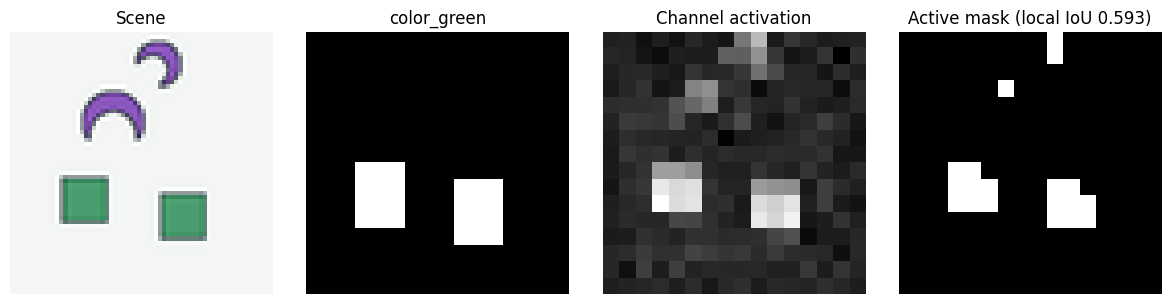

Illustrative BEST local IoU; do not interpret as typical performance.


In [10]:
# Best-aligned *illustration*, chosen within the original dissection dev scenes.
# The aggregate IoU table above, not this selected scene, is the evidence.
chosen = dissection[
    (dissection.baseline == 'trained')
    & (dissection.step == 9000)
    & (dissection['quantile'] == 0.995)
].sort_values('iou', ascending=False).iloc[0]

record = manifest[
    (manifest.schedule == chosen.schedule)
    & (manifest.seed == chosen.seed)
    & (manifest.step == chosen.step)
].iloc[0]
saved = load_diagnostic_checkpoint(record.path)
model = AttributeBindingViT(**saved['model_config'])
model.load_state_dict(saved['model'], strict=True)
model.eval()

rows = distinct_scenes(
    MediumDataset(DATA_DIR / 'id_dev.jsonl').rows, limit=256, seed=67
)
concept = chosen.concept
channel = int(chosen.unit)
best_iou = -1.0
best_scene = None
best_activation = None
best_mask = None

for start in range(0, len(rows), 16):
    subset = rows[start:start + 16]
    images = torch.stack([image_tensor(row['scene']) for row in subset])
    with torch.inference_mode():
        vectors = visual_stages(model, images)[chosen.stage][:, :, channel]

    for row, vector in zip(subset, vectors):
        target = foreground_concept_masks(row['scene'])[concept]
        if not target.any():
            continue
        activity = vector.reshape(16, 16).numpy()
        active = activity >= chosen.threshold
        union = np.logical_or(active, target).sum()
        iou = np.logical_and(active, target).sum() / union if union else 0.0
        if iou > best_iou:
            best_iou = iou
            best_scene = row['scene']
            best_activation = activity
            best_mask = target

assert best_scene is not None, 'No concept-positive scene available'
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
images = [
    image_tensor(best_scene).permute(1, 2, 0).numpy(),
    best_mask,
    best_activation,
    best_activation >= chosen.threshold,
]
titles = [
    'Scene', concept, 'Channel activation',
    f'Active mask (local IoU {best_iou:.3f})',
]
for axis, title, image in zip(axes, titles, images):
    axis.imshow(image, cmap=None if title == 'Scene' else 'gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()
print('Illustrative BEST local IoU; do not interpret as typical performance.')

## 5. SpRAy-style signed-gradient clustering
Clusters are formed from explanation maps separately by target label and split. Cluster IDs are arbitrary **within each seed and checkpoint**; do not average cluster number 0 across runs. The signed maps are gradient×(image−background), not LRP. Inspect graph connected components and eigenspectra before interpreting clusters.

In [11]:
cluster = load_parts('explanation_clusters_*.csv', 30 * 2 * len(SPLITS))
eigens = load_parts('explanation_eigenspectrum_*.csv', 30 * 2 * len(SPLITS))
cluster_summary = cluster.groupby(
    ['schedule', 'seed', 'step', 'split', 'baseline', 'label', 'cluster'],
    dropna=False,
).agg(
    n=('map_index', 'size'),
    n_scenes=('scene_id', 'nunique'),
    accuracy=('correct', 'mean'),
    mean_prob_yes=('prob_yes', 'mean')
).reset_index()
cluster_summary.to_csv(OUT_DIR / 'explanation_cluster_summary.csv', index=False)
print('Graph integrity (disconnected graphs must be treated cautiously):')
display(eigens.groupby(['schedule', 'step', 'baseline', 'split', 'label']).agg(
    max_components=('graph_components', 'max'),
    max_zero_maps=('n_zero_maps', 'max'),
    n_groups=('seed', 'nunique')
).reset_index().head(35))
display(cluster_summary[(cluster_summary.step == 9000) & (cluster_summary.baseline == 'trained')].head(30))

Graph integrity (disconnected graphs must be treated cautiously):


,schedule,step,baseline,split,label,max_components,max_zero_maps,n_groups
0,mixed,5400,random,id_dev,0,1,0,5
1,mixed,5400,random,id_dev,1,1,0,5
2,mixed,5400,random,ood_dev,0,1,0,5
3,mixed,5400,random,ood_dev,1,1,0,5
4,mixed,5400,trained,id_dev,0,1,0,5
5,mixed,5400,trained,id_dev,1,1,0,5
6,mixed,5400,trained,ood_dev,0,1,0,5
7,mixed,5400,trained,ood_dev,1,1,0,5
8,mixed,7200,random,id_dev,0,1,0,5
9,mixed,7200,random,id_dev,1,1,0,5


,schedule,seed,step,split,baseline,label,cluster,n,n_scenes,accuracy,mean_prob_yes
54,mixed,42,9000,id_dev,trained,0,0,20,20,0.500000,0.437919
55,mixed,42,9000,id_dev,trained,0,1,28,28,0.464286,0.481146
56,mixed,42,9000,id_dev,trained,0,2,32,32,0.531250,0.478140
57,mixed,42,9000,id_dev,trained,1,0,24,24,0.750000,0.633647
58,mixed,42,9000,id_dev,trained,1,1,25,25,0.720000,0.605786
59,mixed,42,9000,id_dev,trained,1,2,31,31,0.806452,0.586408
66,mixed,42,9000,ood_dev,trained,0,0,20,20,0.500000,0.493550
67,mixed,42,9000,ood_dev,trained,0,1,29,29,0.241379,0.583742
68,mixed,42,9000,ood_dev,trained,0,2,31,31,0.322581,0.534998
69,mixed,42,9000,ood_dev,trained,1,0,35,35,0.771429,0.627270


### Cluster composition and graph stability

Spectral cluster IDs are arbitrary across seeds. Report whether clusters are dominated by particular target shapes/colors and whether assignments change when the kNN graph is built with 8 rather than 12 or 16 neighbors. A cluster that vanishes under a minor graph change is an exploratory artifact, not a robust learned strategy.

In [12]:
from sklearn.metrics import adjusted_rand_score
from src.medium_visual_world.representation_probing import spray_cluster
composition = cluster.dropna(subset=['cluster']).groupby([
    'schedule',
    'seed',
    'step',
    'split',
    'baseline',
    'label',
    'cluster',
    'shape',
    'color'
]).agg(n=('map_index', 'size'), n_scenes=('scene_id', 'nunique')).reset_index()
composition.to_csv(OUT_DIR / 'explanation_cluster_composition.csv', index=False)
display(composition[(composition.step == 9000) & (composition.baseline == 'trained')].sort_values(
    'n',
    ascending=False
).head(25))
stability = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for split in SPLITS:
            name = f'{split}_{schedule}_seed{seed}_step9000_trained'
            path = OUT_DIR / f'explanation_maps_{name}.npz'
            with np.load(path, allow_pickle=False) as data:
                maps = data['maps']
            meta = pd.read_csv(OUT_DIR / f'explanation_clusters_{name}.csv')
            for label, part in meta.dropna(subset=['cluster']).groupby('label'):
                ordered = part.sort_values('map_index')
                indices = ordered.map_index.to_numpy(int)
                original = ordered.cluster.to_numpy(int)
                for neighbors in (8, 16):
                    candidate, values, gaps, graph = spray_cluster(
                        maps[indices],
                        n_clusters=3,
                        neighbors=min(neighbors, len(indices) - 2),
                        seed=seed
                    )
                    stability.append({
                        'schedule': schedule,
                        'seed': seed,
                        'step': 9000,
                        'split': split,
                        'label': int(label),
                        'neighbors': neighbors,
                        'n_maps': len(indices),
                        'ARI_vs_original_k12': adjusted_rand_score(original, candidate),
                        'min_eigenvalue': float(values[0]),
                        'largest_eigengap': float(max(gaps))
                    })
stability = pd.DataFrame(stability)
stability.to_csv(OUT_DIR / 'explanation_graph_stability.csv', index=False)
display(stability.groupby([
    'schedule',
    'split',
    'neighbors'
]).ARI_vs_original_k12.agg(['mean', 'std']).reset_index())


,schedule,seed,step,split,baseline,label,cluster,shape,color,n,n_scenes
5902,prereq_mixed_pair_focus,46,9000,ood_dev,trained,1,1,triangle,purple,18,18
5899,prereq_mixed_pair_focus,46,9000,ood_dev,trained,1,1,circle,green,18,18
5282,prereq_mixed_pair_focus,45,9000,ood_dev,trained,1,1,circle,green,17,17
5285,prereq_mixed_pair_focus,45,9000,ood_dev,trained,1,1,triangle,purple,17,17
1735,mixed,44,9000,ood_dev,trained,0,2,triangle,purple,17,17
4101,prereq_mixed_pair_focus,43,9000,ood_dev,trained,1,0,circle,green,16,16
3541,prereq_mixed_pair_focus,42,9000,ood_dev,trained,0,2,triangle,purple,15,15
1153,mixed,43,9000,ood_dev,trained,1,0,triangle,purple,15,15
2955,mixed,46,9000,ood_dev,trained,1,0,circle,green,14,14
3546,prereq_mixed_pair_focus,42,9000,ood_dev,trained,1,1,circle,green,14,14


,schedule,split,neighbors,mean,std
0,mixed,id_dev,8,0.347811,0.152205
1,mixed,id_dev,16,0.428813,0.202257
2,mixed,ood_dev,8,0.421353,0.149925
3,mixed,ood_dev,16,0.422861,0.183332
4,prereq_mixed_pair_focus,id_dev,8,0.370448,0.181600
5,prereq_mixed_pair_focus,id_dev,16,0.469281,0.203195
6,prereq_mixed_pair_focus,ood_dev,8,0.371622,0.192109
7,prereq_mixed_pair_focus,ood_dev,16,0.418989,0.232382


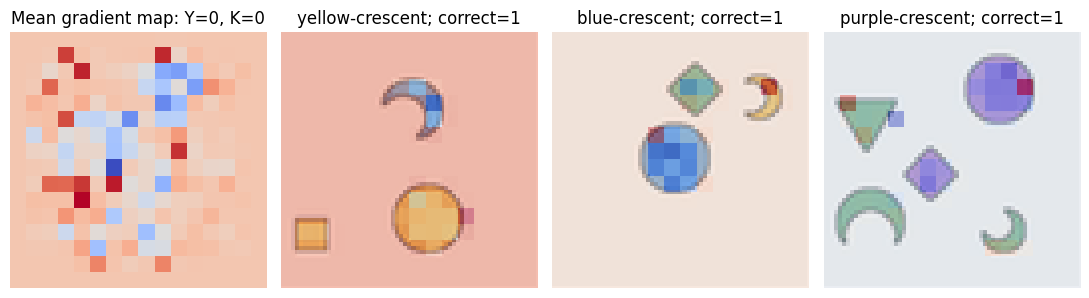

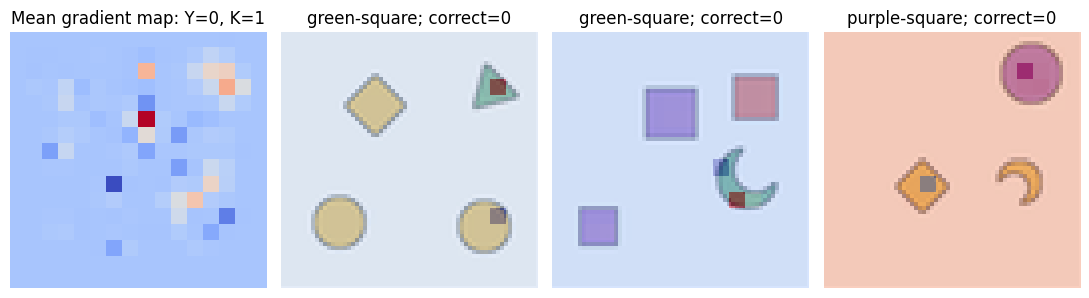

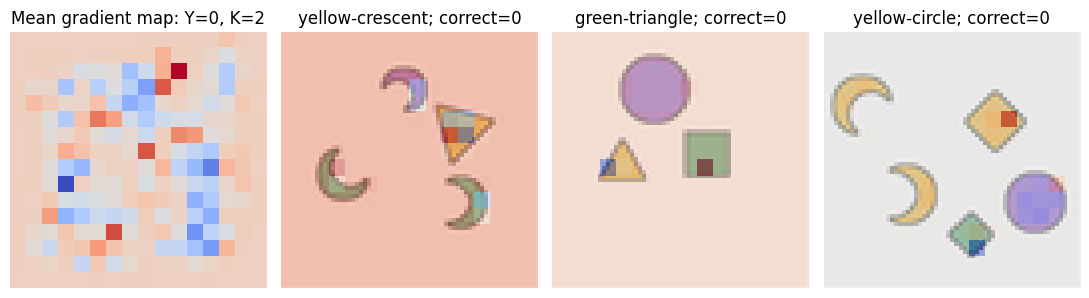

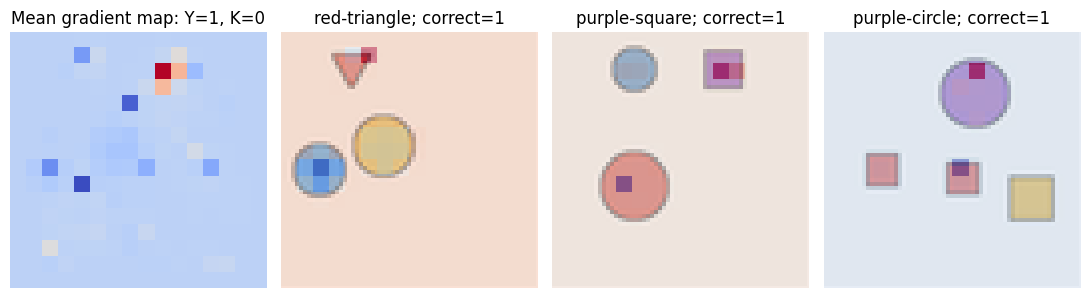

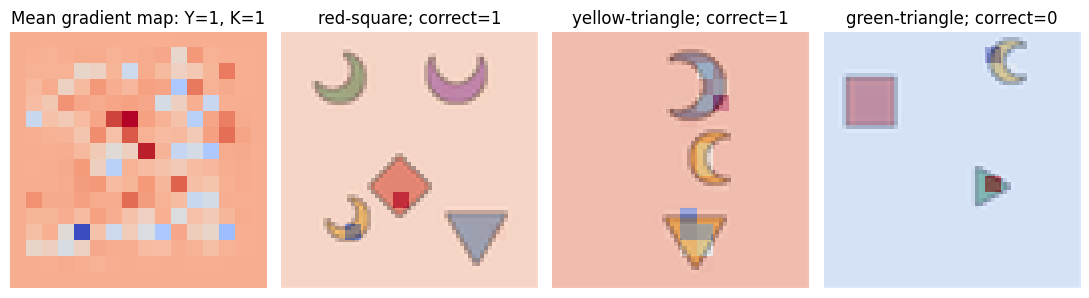

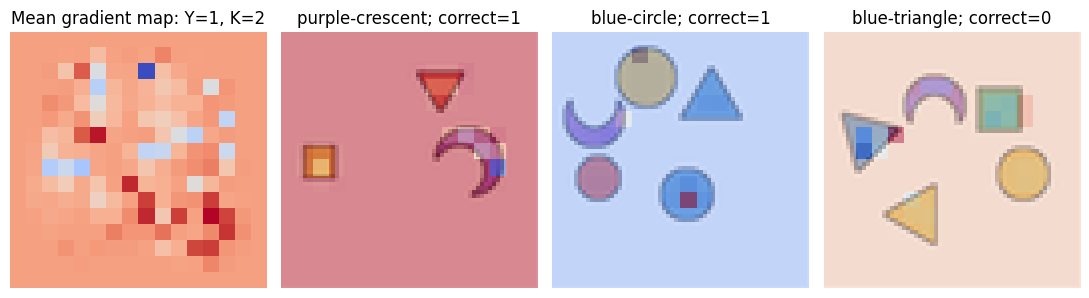

In [13]:
file = OUT_DIR / 'explanation_maps_id_dev_prereq_mixed_pair_focus_seed42_step9000_trained.npz'
meta = pd.read_csv(
    OUT_DIR / 'explanation_clusters_id_dev_prereq_mixed_pair_focus_seed42_step9000_trained.csv'
)
with np.load(file, allow_pickle=False) as data:
    maps = data['maps']
scene_map = {r['scene_id']: r['scene'] for r in MediumDataset(DATA_DIR / 'id_dev.jsonl').rows}
for (label, cluster_id), group in meta.dropna(subset=['cluster']).groupby(['label', 'cluster']):
    indices = group.map_index.to_numpy(int)
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))
    axes[0].imshow(maps[indices].mean(0), cmap='coolwarm')
    axes[0].set_title(f'Mean gradient map: Y={label}, K={int(cluster_id)}')
    for ax, idx in zip(axes[1:], indices[:3]):
        example = meta.loc[meta.map_index == idx].iloc[0]
        ax.imshow(image_tensor(scene_map[example.scene_id]).permute(1, 2, 0).numpy())
        ax.imshow(maps[idx], cmap='coolwarm', alpha=0.5, extent=(0, 64, 64, 0))
        ax.set_title(f"{example.color}-{example['shape']}; correct={example.correct}")
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


## 6. Five-seed paired summaries and interpretation gate
Summaries below use **five independent model seeds**, not tens of thousands of correlated generated questions as independent replications. Use scene bootstrap only as a complementary within-model check. Do not claim a causal head bottleneck from linear probes, a causal attention strategy from spectral clusters, or an absent Shape feature from low channel IoU.

In [14]:
probe_main = probe[
    (probe.probe_label == 'true')
    & (probe.baseline == 'trained')
    & (probe.stage == 'fused')
    & (probe.split == 'id_dev')
    & (probe.task == 'shape')
].copy()
probe_ci = mean_sd_ci(probe_main, ['schedule', 'step', 'task', 'stage', 'split'], 'accuracy')
probe_ci.to_csv(OUT_DIR / 'probe_shape_five_seed_ci.csv', index=False)
display(probe_ci)
cf_main = pairs[
    (pairs.edit == 'binding_swap') & (pairs.split == 'id_dev')
].groupby(['schedule', 'seed', 'step'], as_index=False).agg(
    both_correct=('both_correct', 'mean'),
    n_scenes=('scene_id', 'nunique')
)
cf_ci = mean_sd_ci(cf_main, ['schedule', 'step'], 'both_correct')
cf_ci.to_csv(OUT_DIR / 'binding_swap_five_seed_ci.csv', index=False)
display(cf_ci)
print(
    'Checks: inspect subgroup support, ID/OOD separately, and random controls '
    'before making mechanism claims.'
)


,schedule,step,task,stage,split,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
0,mixed,5400,shape,fused,id_dev,0.530822,0.030539,0.492903,0.568741,5
1,mixed,7200,shape,fused,id_dev,0.532583,0.023846,0.502974,0.562192,5
2,mixed,9000,shape,fused,id_dev,0.532290,0.025202,0.500998,0.563582,5
3,prereq_mixed_pair_focus,5400,shape,fused,id_dev,0.531605,0.031099,0.492990,0.570220,5
4,prereq_mixed_pair_focus,7200,shape,fused,id_dev,0.535519,0.020593,0.509949,0.561089,5
5,prereq_mixed_pair_focus,9000,shape,fused,id_dev,0.539335,0.025034,0.508251,0.570418,5


,schedule,step,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
0,mixed,5400,0.169788,0.028682,0.134174,0.205402,5
1,mixed,7200,0.197350,0.048813,0.136740,0.257960,5
2,mixed,9000,0.232686,0.041021,0.181751,0.283620,5
3,prereq_mixed_pair_focus,5400,0.034452,0.040134,-0.015380,0.084285,5
4,prereq_mixed_pair_focus,7200,0.322438,0.047330,0.263671,0.381206,5
5,prereq_mixed_pair_focus,9000,0.248233,0.029577,0.211508,0.284958,5


Checks: inspect subgroup support, ID/OOD separately, and random controls before making mechanism claims.


## 7. Predeclared paired diagnostics and five-seed uncertainty

Use *independent trained seeds* as the replication unit. The following differences are paired by `(curriculum, seed, checkpoint, split)` and summarized with five-seed t intervals. This is exploratory inference over five seeds, not a multiplicity-adjusted confirmatory test.

In [15]:
conj = unique[(unique.task == 'conjunction') & unique.logic_case.isin([
    'missing_color',
    'missing_shape'
])]
conj_case = conj.groupby(['schedule', 'seed', 'step', 'split', 'logic_case'], as_index=False).agg(
    accuracy=('correct', 'mean'),
    n_questions=('correct', 'size'),
    n_scenes=('scene_id', 'nunique')
)
conj_pivot = conj_case.pivot(
    index=['schedule', 'seed', 'step', 'split'],
    columns='logic_case',
    values='accuracy'
).reset_index()
assert conj_pivot[['missing_color', 'missing_shape']].notna().all().all()
conj_pivot['shape_minus_color_negative_acc'] = conj_pivot.missing_shape - conj_pivot.missing_color
conj_ci = mean_sd_ci(conj_pivot, ['schedule', 'step', 'split'], 'shape_minus_color_negative_acc')
conj_ci.to_csv(OUT_DIR / 'conjunction_shortcut_five_seed_ci.csv', index=False)
display(conj_ci)
shape_probe = probe[(probe.probe_label == 'true') & (probe.stage == 'fused') & (probe.task == 'shape')]
probe_pivot = shape_probe.pivot(
    index=['schedule', 'seed', 'step', 'split'],
    columns='baseline',
    values='accuracy'
).reset_index()
assert probe_pivot[['trained', 'random']].notna().all().all()
probe_pivot['trained_minus_random'] = probe_pivot.trained - probe_pivot.random
contrast = mean_sd_ci(probe_pivot, ['schedule', 'step', 'split'], 'trained_minus_random')
contrast.to_csv(OUT_DIR / 'shape_probe_vs_random_five_seed_ci.csv', index=False)
display(contrast)
cf_all = pairs.groupby(['schedule', 'seed', 'step', 'split', 'edit'], as_index=False).agg(
    both_correct=('both_correct', 'mean'),
    n_scenes=('scene_id', 'nunique')
)
cf_all_ci = mean_sd_ci(cf_all, ['schedule', 'step', 'split', 'edit'], 'both_correct')
cf_all_ci.to_csv(OUT_DIR / 'counterfactual_five_seed_ci.csv', index=False)
display(cf_all_ci[cf_all_ci.step == 9000])


,schedule,step,split,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
0,mixed,5400,id_dev,-0.828566,0.060982,-0.904286,-0.752847,5
1,mixed,5400,ood_dev,-0.826866,0.064286,-0.906687,-0.747044,5
2,mixed,7200,id_dev,-0.795019,0.029775,-0.831989,-0.758048,5
3,mixed,7200,ood_dev,-0.814100,0.029592,-0.850843,-0.777356,5
4,mixed,9000,id_dev,-0.755111,0.038898,-0.803410,-0.706812,5
5,mixed,9000,ood_dev,-0.784875,0.033309,-0.826234,-0.743516,5
6,prereq_mixed_pair_focus,5400,id_dev,-0.789893,0.068246,-0.874631,-0.705154,5
7,prereq_mixed_pair_focus,5400,ood_dev,-0.824220,0.064946,-0.904861,-0.743579,5
8,prereq_mixed_pair_focus,7200,id_dev,-0.395074,0.134247,-0.561764,-0.228384,5
9,prereq_mixed_pair_focus,7200,ood_dev,-0.405725,0.129345,-0.566328,-0.245122,5


,schedule,step,split,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
0,mixed,5400,id_dev,0.022407,0.041900,-0.029618,0.074432,5
1,mixed,5400,ood_dev,0.010376,0.036741,-0.035244,0.055995,5
2,mixed,7200,id_dev,0.024168,0.035260,-0.019613,0.067949,5
3,mixed,7200,ood_dev,0.010018,0.033317,-0.031350,0.051386,5
4,mixed,9000,id_dev,0.023875,0.039739,-0.025468,0.073217,5
5,mixed,9000,ood_dev,0.008706,0.030108,-0.028678,0.046090,5
6,prereq_mixed_pair_focus,5400,id_dev,0.023190,0.041156,-0.027913,0.074292,5
7,prereq_mixed_pair_focus,5400,ood_dev,0.005486,0.030357,-0.032207,0.043179,5
8,prereq_mixed_pair_focus,7200,id_dev,0.027104,0.037403,-0.019338,0.073545,5
9,prereq_mixed_pair_focus,7200,ood_dev,0.007275,0.028794,-0.028478,0.043027,5


,schedule,step,split,edit,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
12,mixed,9000,id_dev,binding_swap,0.232686,0.041021,0.181751,0.283620,5
13,mixed,9000,id_dev,color_insert,0.882014,0.030489,0.844158,0.919871,5
14,mixed,9000,id_dev,shape_insert,0.083259,0.022526,0.055289,0.111229,5
15,mixed,9000,ood_dev,binding_swap,0.230491,0.044453,0.175296,0.285687,5
16,mixed,9000,ood_dev,color_insert,0.873126,0.030374,0.835411,0.910841,5
17,mixed,9000,ood_dev,shape_insert,0.071094,0.020326,0.045856,0.096331,5
30,prereq_mixed_pair_focus,9000,id_dev,binding_swap,0.248233,0.029577,0.211508,0.284958,5
31,prereq_mixed_pair_focus,9000,id_dev,color_insert,0.885468,0.046689,0.827496,0.943440,5
32,prereq_mixed_pair_focus,9000,id_dev,shape_insert,0.094222,0.038867,0.045962,0.142482,5
33,prereq_mixed_pair_focus,9000,ood_dev,binding_swap,0.231896,0.005823,0.224666,0.239125,5


## Refined Shape probes: spatial layout × color-balanced fitting

The original mean-pooled probe above is retained as the historical baseline. Here the matched `mean` and `spatial` readouts use identical 5×5 sampling positions. The `recolored_balanced` regime changes only **diagnostic decoder training images**, never ViT weights. Evaluate ID-dev and OOD-dev separately; OOD colors are no longer unseen by a color-balanced diagnostic decoder.

In [16]:
refined = load_parts('refined_probe_metrics_*.csv', 30)
refined_predictions = load_parts('refined_probe_predictions_*.csv', 30)
silhouette = pd.read_csv(OUT_DIR / 'refined_probe_silhouette_metrics.csv')
balance = pd.read_csv(OUT_DIR / 'refined_probe_training_balance.csv')

refined.to_csv(OUT_DIR / 'refined_probe_metrics_all.csv', index=False)
refined_summary = mean_sd_ci(
    refined, ['schedule', 'step', 'baseline', 'stage', 'regime',
              'readout', 'split'], 'accuracy')
refined_summary.to_csv(OUT_DIR / 'refined_probe_five_seed_summary.csv', index=False)
print('Raw-image silhouette baseline:')
display(silhouette)
print('Effective probe training distribution:')
display(balance.groupby(['regime', 'shape']).n_objects.sum().reset_index())
print('Final-step frozen feature decoding:')
display(refined_summary[
    (refined_summary.step == 9000)
    & (refined_summary.stage == 'fused')
].sort_values(['schedule', 'split', 'baseline', 'regime', 'readout']))

Raw-image silhouette baseline:


,regime,split,accuracy,macro_f1,n_eval_objects
0,original,id_dev,1.0,1.0,2044
1,recolored_balanced,id_dev,1.0,1.0,2044
2,original,ood_dev,1.0,1.0,1677
3,recolored_balanced,ood_dev,1.0,1.0,1677


Effective probe training distribution:


,regime,shape,n_objects
0,original,circle,1243
1,original,crescent,1151
2,original,square,1253
3,original,triangle,1179
4,recolored_balanced,circle,1243
5,recolored_balanced,crescent,1151
6,recolored_balanced,square,1253
7,recolored_balanced,triangle,1179


Final-step frozen feature decoding:


,schedule,step,baseline,stage,regime,readout,split,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
108,mixed,9000,random,fused,original,mean,id_dev,0.514188,0.023361,0.485182,0.543194,5
110,mixed,9000,random,fused,original,spatial,id_dev,0.794129,0.010141,0.781537,0.806721,5
112,mixed,9000,random,fused,recolored_balanced,mean,id_dev,0.470157,0.022116,0.442696,0.497617,5
114,mixed,9000,random,fused,recolored_balanced,spatial,id_dev,0.750294,0.018334,0.727529,0.773058,5
124,mixed,9000,shuffled_label_control,fused,recolored_balanced,spatial,id_dev,0.254892,0.012488,0.239387,0.270398,5
134,mixed,9000,trained,fused,original,mean,id_dev,0.519765,0.018807,0.496413,0.543118,5
136,mixed,9000,trained,fused,original,spatial,id_dev,0.795695,0.016535,0.775164,0.816226,5
138,mixed,9000,trained,fused,recolored_balanced,mean,id_dev,0.474560,0.013465,0.457841,0.491279,5
140,mixed,9000,trained,fused,recolored_balanced,spatial,id_dev,0.751566,0.014357,0.733739,0.769392,5
109,mixed,9000,random,fused,original,mean,ood_dev,0.464878,0.018450,0.441969,0.487786,5


In [17]:
from scipy.stats import t

comparisons = (
    ('spatial_vs_mean_original', 'spatial', 'original', 'mean', 'original'),
    ('spatial_vs_mean_balanced', 'spatial', 'recolored_balanced', 'mean', 'recolored_balanced'),
    ('balanced_vs_original_mean', 'mean', 'recolored_balanced', 'mean', 'original'),
    ('balanced_vs_original_spatial', 'spatial', 'recolored_balanced', 'spatial', 'original'),
)
contrasts = []
keys = ['schedule', 'seed', 'step', 'baseline', 'stage', 'split']
for label, readout_a, regime_a, readout_b, regime_b in comparisons:
    a = refined[(refined.readout == readout_a) & (refined.regime == regime_a)]
    b = refined[(refined.readout == readout_b) & (refined.regime == regime_b)]
    joined = a[keys + ['accuracy']].merge(
        b[keys + ['accuracy']], on=keys, suffixes=('_a', '_b'),
        validate='one_to_one')
    joined['contrast'] = label
    joined['regime'] = regime_a
    joined['readout'] = readout_a
    joined['difference_pp'] = 100 * (joined.accuracy_a - joined.accuracy_b)
    contrasts.append(joined)

# Attribution to trained encoder rather than raw/random patch geometry.
keys = ['schedule', 'seed', 'step', 'stage', 'regime', 'readout', 'split']
trained = refined[refined.baseline == 'trained']
random = refined[refined.baseline == 'random']
learned = trained[keys + ['accuracy']].merge(
    random[keys + ['accuracy']], on=keys, suffixes=('_a', '_b'),
    validate='one_to_one')
learned['contrast'] = 'trained_minus_random'
learned['difference_pp'] = 100 * (learned.accuracy_a - learned.accuracy_b)
learned['baseline'] = 'trained_vs_random'
contrasts.append(learned)

paired = pd.concat(contrasts, ignore_index=True)
paired.to_csv(OUT_DIR / 'refined_probe_paired_by_seed.csv', index=False)
paired_ci = mean_sd_ci(
    paired.rename(columns={'difference_pp': 'paired_difference_pp'}),
    ['schedule', 'step', 'baseline', 'stage', 'split',
     'regime', 'readout', 'contrast'],
    'paired_difference_pp')
paired_ci.to_csv(OUT_DIR / 'refined_probe_paired_five_seed_ci.csv', index=False)
display(paired_ci[(paired_ci.step == 9000)
                  & (paired_ci.stage == 'fused')
                  & (paired_ci.baseline == 'trained')])

,schedule,step,baseline,stage,split,regime,readout,contrast,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
176,mixed,9000,trained,fused,id_dev,original,spatial,spatial_vs_mean_original,27.592955,1.073538,26.259982,28.925928,5
177,mixed,9000,trained,fused,id_dev,recolored_balanced,mean,balanced_vs_original_mean,-4.520548,1.065481,-5.843517,-3.197579,5
178,mixed,9000,trained,fused,id_dev,recolored_balanced,spatial,balanced_vs_original_spatial,-4.412916,1.452300,-6.216185,-2.609647,5
179,mixed,9000,trained,fused,id_dev,recolored_balanced,spatial,spatial_vs_mean_balanced,27.700587,2.113480,25.076355,30.324819,5
180,mixed,9000,trained,fused,ood_dev,original,spatial,spatial_vs_mean_original,27.716160,1.964816,25.276519,30.155801,5
181,mixed,9000,trained,fused,ood_dev,recolored_balanced,mean,balanced_vs_original_mean,2.468694,0.638907,1.675386,3.262002,5
182,mixed,9000,trained,fused,ood_dev,recolored_balanced,spatial,balanced_vs_original_spatial,2.611807,1.407578,0.864068,4.359546,5
183,mixed,9000,trained,fused,ood_dev,recolored_balanced,spatial,spatial_vs_mean_balanced,27.859273,1.497540,25.999831,29.718714,5
392,prereq_mixed_pair_focus,9000,trained,fused,id_dev,original,spatial,spatial_vs_mean_original,26.966732,1.173353,25.509822,28.423642,5
393,prereq_mixed_pair_focus,9000,trained,fused,id_dev,recolored_balanced,mean,balanced_vs_original_mean,-4.677104,0.310579,-5.062738,-4.291469,5


In [18]:
shape_cells = (refined_predictions[
    (refined_predictions.stage == 'fused')
    & (refined_predictions.step == 9000)
].groupby(['schedule', 'seed', 'baseline', 'regime', 'readout',
           'split', 'shape', 'color'], as_index=False)
 .agg(n_objects=('correct', 'size'),
      accuracy=('correct', 'mean')))
shape_cells.to_csv(OUT_DIR / 'refined_probe_shape_color_by_seed.csv', index=False)
geometry = (refined_predictions[
    (refined_predictions.baseline == 'trained')
    & (refined_predictions.stage == 'fused')
].groupby(['schedule', 'seed', 'step', 'regime', 'readout',
           'split', 'shape', 'radius'], as_index=False)
 .agg(n_objects=('correct', 'size'), accuracy=('correct', 'mean')))
geometry.to_csv(OUT_DIR / 'refined_probe_shape_radius_by_seed.csv', index=False)

print('Held-out Shape×Color probe predictions, final checkpoint:')
from src.medium_visual_world.generate import HOLDOUT
heldout = shape_cells[shape_cells.apply(
    lambda row: (row['color'], row['shape']) in HOLDOUT, axis=1)]
display(heldout.groupby(['schedule', 'baseline', 'regime', 'readout',
                         'split']).accuracy.agg(['mean', 'std']).reset_index())

Held-out Shape×Color probe predictions, final checkpoint:


,schedule,baseline,regime,readout,split,mean,std
0,mixed,random,original,mean,ood_dev,0.216626,0.213340
1,mixed,random,original,spatial,ood_dev,0.432089,0.342651
2,mixed,random,recolored_balanced,mean,ood_dev,0.527628,0.347131
3,mixed,random,recolored_balanced,spatial,ood_dev,0.774491,0.186353
4,mixed,trained,original,mean,ood_dev,0.133107,0.123730
5,mixed,trained,original,spatial,ood_dev,0.350296,0.387190
6,mixed,trained,recolored_balanced,mean,ood_dev,0.481187,0.266009
7,mixed,trained,recolored_balanced,spatial,ood_dev,0.785956,0.178408
8,prereq_mixed_pair_focus,random,original,mean,ood_dev,0.216626,0.213340
9,prereq_mixed_pair_focus,random,original,spatial,ood_dev,0.432089,0.342651


In [19]:
selected = refined_predictions[
    (refined_predictions.schedule == 'prereq_mixed_pair_focus')
    & (refined_predictions.seed == 42)
    & (refined_predictions.step == 9000)
    & (refined_predictions.baseline == 'trained')
    & (refined_predictions.regime == 'recolored_balanced')
    & (refined_predictions.readout == 'spatial')
    & (refined_predictions.split == 'ood_dev')
]
print('Refined spatial Shape probe confusion matrix on OOD-dev (one model):')
display(pd.crosstab(selected.target, selected.prediction,
                    rownames=['True Shape'], colnames=['Predicted Shape']))
print('Shuffled-label negative control (chance is 25% for four balanced classes):')
display(refined_summary[
    (refined_summary.baseline == 'shuffled_label_control')
    & (refined_summary.step == 9000)
])

Refined spatial Shape probe confusion matrix on OOD-dev (one model):


Predicted Shape,circle,crescent,square,triangle
True Shape,,,,
circle,354,0,63,18
crescent,0,408,0,2
square,73,0,217,116
triangle,13,0,101,312


Shuffled-label negative control (chance is 25% for four balanced classes):


,schedule,step,baseline,stage,regime,readout,split,mean,sd_between_seeds,ci95_low,ci95_high,n_seeds
124,mixed,9000,shuffled_label_control,fused,recolored_balanced,spatial,id_dev,0.254892,0.012488,0.239387,0.270398,5
125,mixed,9000,shuffled_label_control,fused,recolored_balanced,spatial,ood_dev,0.247943,0.007222,0.238975,0.256911,5
274,prereq_mixed_pair_focus,9000,shuffled_label_control,fused,recolored_balanced,spatial,id_dev,0.255871,0.014636,0.237698,0.274044,5
275,prereq_mixed_pair_focus,9000,shuffled_label_control,fused,recolored_balanced,spatial,ood_dev,0.254025,0.011904,0.239245,0.268805,5


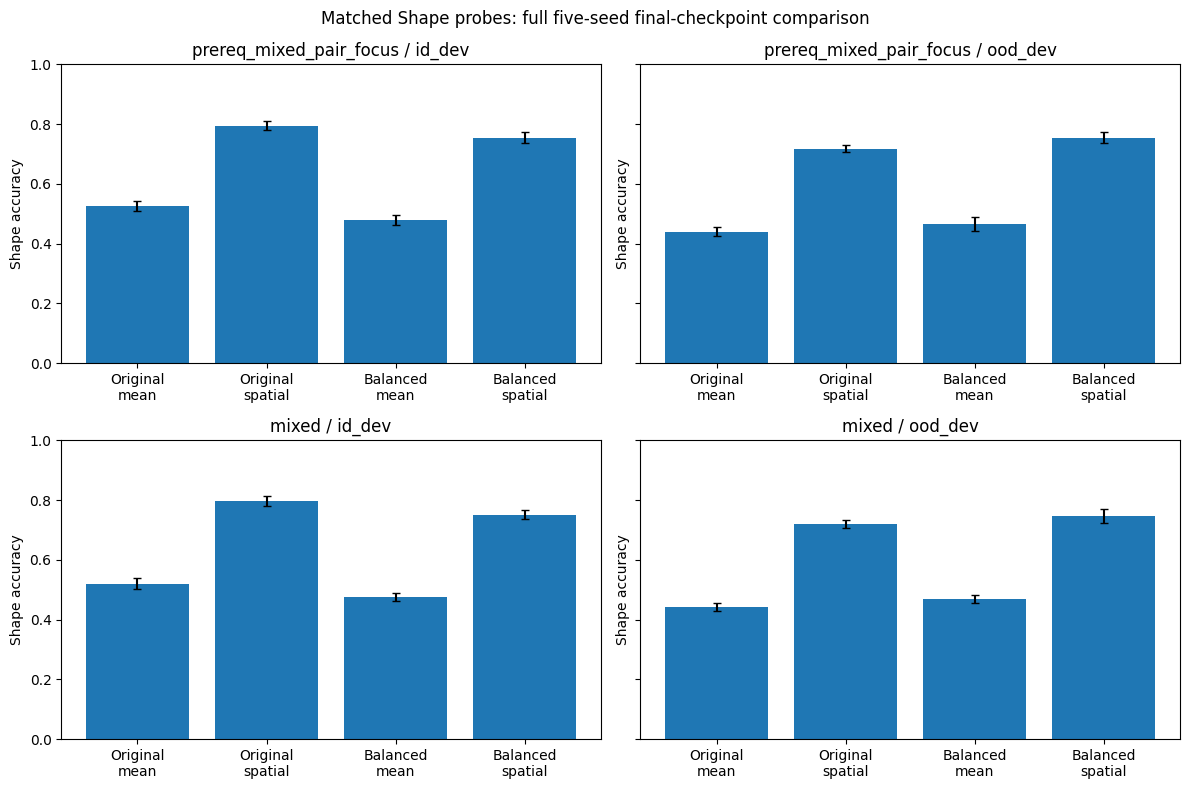

In [20]:
plot_data = refined_summary[
    (refined_summary.step == 9000)
    & (refined_summary.stage == 'fused')
    & (refined_summary.baseline == 'trained')
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for row_index, schedule in enumerate(SCHEDULES):
    for col_index, split in enumerate(SPLITS):
        axis = axes[row_index, col_index]
        subset = plot_data[(plot_data.schedule == schedule)
                           & (plot_data.split == split)]
        order = [
            ('original', 'mean'), ('original', 'spatial'),
            ('recolored_balanced', 'mean'),
            ('recolored_balanced', 'spatial'),
        ]
        means = [subset[(subset.regime == regime)
                        & (subset.readout == readout)].iloc[0]['mean']
                 for regime, readout in order]
        stds = [subset[(subset.regime == regime)
                       & (subset.readout == readout)].iloc[0]['sd_between_seeds']
                for regime, readout in order]
        axis.bar(range(4), means, yerr=stds, capsize=3)
        axis.set_xticks(range(4), ['Original\nmean', 'Original\nspatial',
                                   'Balanced\nmean', 'Balanced\nspatial'])
        axis.set_title(f'{schedule} / {split}')
        axis.set_ylim(0, 1)
        axis.set_ylabel('Shape accuracy')
fig.suptitle('Matched Shape probes: full five-seed final-checkpoint comparison')
fig.tight_layout()
fig.savefig(OUT_DIR / 'refined_probe_final_comparison.png', dpi=170)
plt.show()